# Three follow-up checks

The main question is whether popular users received later positive ratings for reasons beyond how long and how actively they appear in the records. This notebook reads the outputs from `scripts/flagship_checks.py`; the script contains the complete event-by-event calculation. Run the four analysis scripts listed in the README first.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'outputs' / 'flagship'
matched = pd.read_csv(OUT / 'matched_target_choice.csv')
rewired = pd.read_csv(OUT / 'degree_preserving_null.csv')
evolution = pd.read_csv(OUT / 'structural_evolution.csv')
metadata = json.loads((OUT / 'metadata.json').read_text())


## 1. Compare users with similar opportunity

At each positive rating, the script looks **before** that rating. It groups possible recipients by time since their first observed positive rating and by the number of positive ratings they gave or received in the previous 90 days. It compares the actual recipient with eligible users in the same two groups. The chosen recipient is included in the possible recipients. A ratio above 1 means the degree group received more ratings than equal choice within those matched groups predicts. Observed tenure and activity are only rough proxies for opportunity; they do not measure platform visibility or actual trades.


,prior_positive_in_degree,observed_target_events,matched_null_expected_events,observed_over_expected
0,0,601,156.234,3.847
1,1,3087,3346.705,0.922
2,2-3,3710,4797.392,0.773
3,4-7,4117,5486.153,0.750
4,8-15,4198,5158.026,0.814
5,16-31,3986,3623.942,1.100
6,32+,7294,4424.548,1.649


Existing-target events covered: 26993
Coverage: 99.48 %


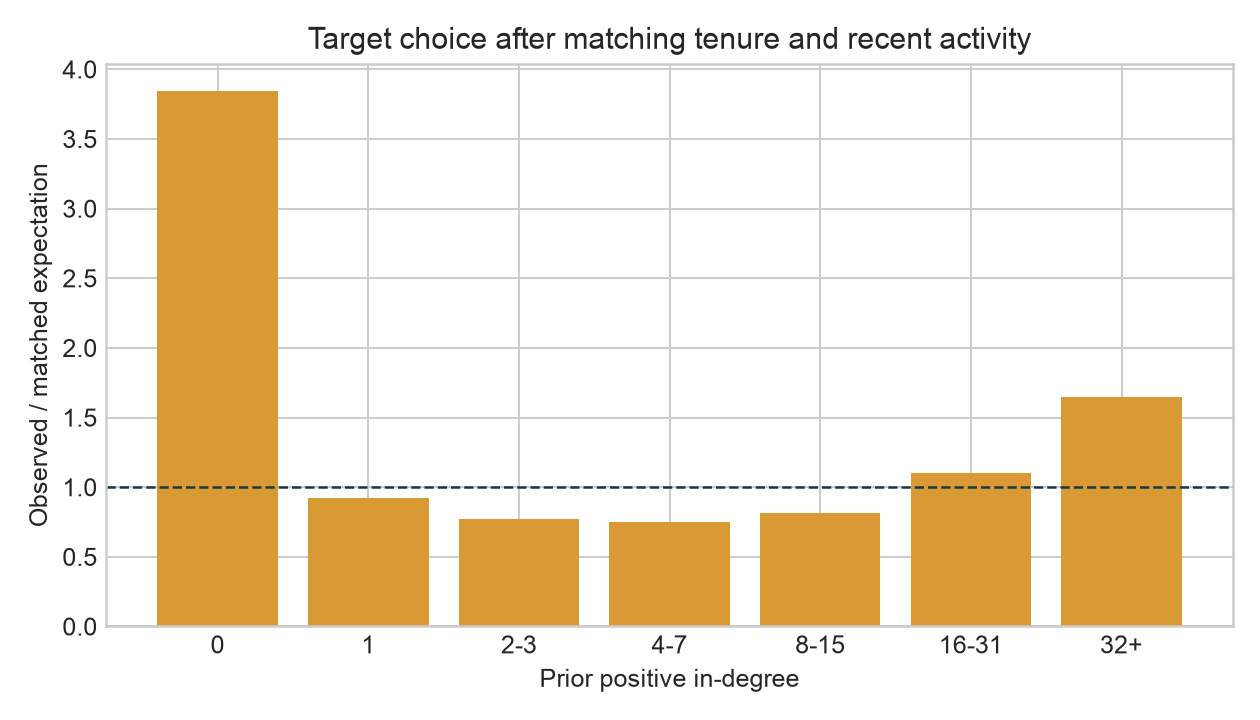

In [2]:
display(matched.round(3))
print('Existing-target events covered:', metadata['matched_choice']['matched_events'])
print('Coverage:', round(100 * metadata['matched_choice']['coverage_of_existing_target_events'], 2), '%')
display(Image(filename=str(OUT / 'matched_target_choice.png')))


The 32+ degree ratio changes from 12.70 under the earlier uniform benchmark to about 1.65 here. That large change means observed tenure and activity explain much of the apparent preference for hubs. The remaining association is still observational. The degree-zero group also has an elevated ratio, so the relationship is not a simple straight-line growth law.


## 2. Keep every user's degree, randomize the links

A degree-preserving rewire swaps endpoints of two links while keeping each user's number of projected positive links fixed. The script repeats this for eight seeds, with ten successful swaps per original link. If observed clustering exceeds these rewired versions, the degree sequence alone does not explain all the observed triangles. This comparison uses the **undirected positive projection**, so it does not retain rating direction or sign.


,network,seed,transitivity,edges
0,observed,-1,0.0570,18591
1,degree_preserving_rewire,2026,0.0439,18591
2,degree_preserving_rewire,2027,0.0440,18591
3,degree_preserving_rewire,2028,0.0432,18591
4,degree_preserving_rewire,2029,0.0438,18591
5,degree_preserving_rewire,2030,0.0431,18591
6,degree_preserving_rewire,2031,0.0420,18591
7,degree_preserving_rewire,2032,0.0436,18591
8,degree_preserving_rewire,2033,0.0407,18591


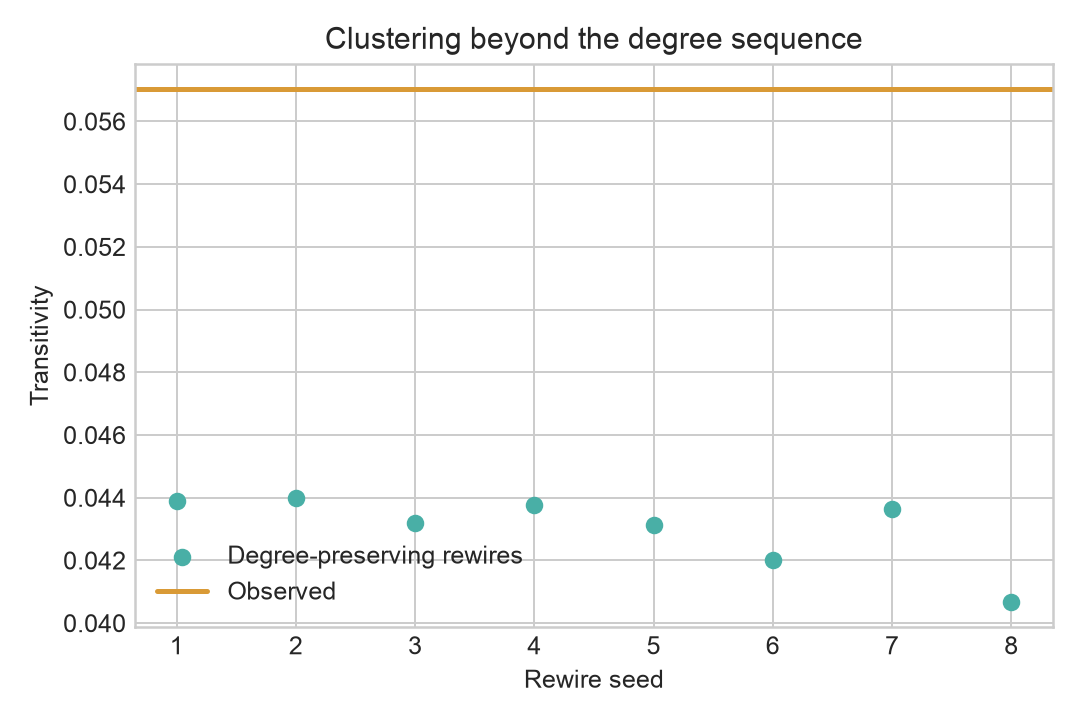

In [3]:
display(rewired.round(4))
display(Image(filename=str(OUT / 'degree_preserving_null.png')))


## 3. Watch network shape change

Each year-end graph keeps all positive ratings recorded so far. Largest-component share and transitivity are calculated on its undirected projection; reciprocity uses the directed positive graph. These are changes in the **cumulative record**, not proof that old ratings were still active at that date. The active-user denominator differs from the full 5,881-user graph, which includes users never seen in a positive rating.


,year_end,active_users,directed_positive_ratings,positive_projection_edges,largest_component_share_of_active,projection_transitivity,directed_reciprocity
0,2011,1631,7745,4339,0.9963,0.0460,0.8795
1,2012,3116,16367,9386,0.9981,0.0539,0.8531
2,2013,4991,27505,15890,0.9964,0.0485,0.8446
3,2014,5455,31060,18032,0.9963,0.0549,0.8389
4,2015,5571,31989,18571,0.9961,0.0569,0.8389


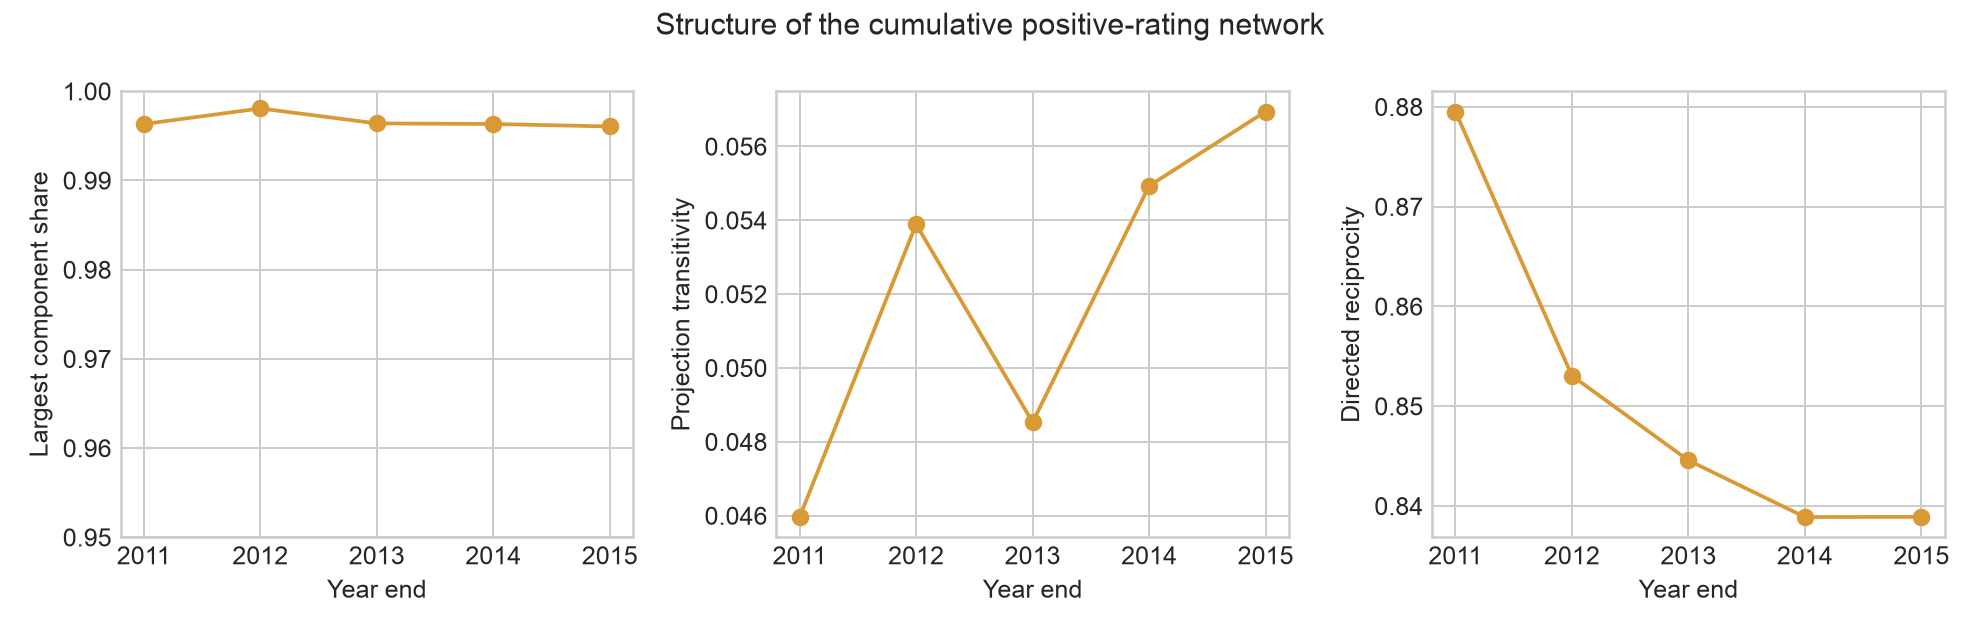

In [4]:
display(evolution.round(4))
display(Image(filename=str(OUT / 'structural_evolution.png')))


## What can we conclude?

The observed graph has more transitivity than the eight degree-preserving rewires. Its reciprocity falls across the 2011–2015 cumulative snapshots, while transitivity rises overall with a 2013 dip. Highly rated users remain overrepresented after coarse matching, but the ratio is far smaller than under uniform choice. None of these comparisons identifies a causal mechanism for how raters chose users.
